# Day 4 · Explain the model and test its probabilities

Two different questions: *which features did the model lean on?* (explanation) and *can its probabilities be taken at face value?* (calibration). We separate the data into roles (fit, calibration, policy, evaluation), explain a class-weighted LightGBM with permutation importance and SHAP, fit a sigmoid calibrator on its own period, and test whether a review zone fits the 12% capacity.

## 1. Setup

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7",
                                   "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d",
                                 "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"{RAW_BASE}/{revision}/{relative}", ROOT / relative, digest)

LAB_REVISION = "4f6892d5c02923b5f8e3c78f4fcead73b043570f"
SUPPORT_HASHES = {
    "scripts/day4_trust.py": "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c",
    "data/day4_shap_example.npz": "de6eefb4f0b1dfd54d4a71e2b73cf8383cea6386e661f8af8662d478cd957e2b",
    "data/day4_shap_example.json": "8169c70dc327a7ffdff748c365d71544fe951f3b196974e33f09dccb580a8122",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 4 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 4 setup verified


## 2. Separate fit, calibration, policy and evaluation

The target is a default within 90 days of applying. Each role gets its own period and its own customers: the model is **fit** on the oldest rows, the sigmoid is learned on the **calibration** rows, the review threshold is chosen on the **policy** rows, and everything is scored once on the **evaluation** rows. Gap periods and customer overlaps are excluded. Nothing is retuned after the evaluation numbers appear.

In [2]:
import json
import os
import platform
import zipfile
from dataclasses import asdict

import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit

from data_checks import validate_frame
from day2_validation import deduplicate_applications
from day4_trust import (
    ROLES, TARGET, ShapBudgetExpired, TrustConfig, choose_policy_threshold,
    cluster_bootstrap, explain_sample, fit_and_calibrate, load_shap_example,
    local_stability, map_probability, permutation_report, probability_metrics,
    reason_codes, reflection_check, reliability_table, review_audit, split_roles,
    transport_threshold
)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")

config = TrustConfig() if FAST_MODE else TrustConfig(
    trees=160,
    shap_rows=600,
    permutation_repeats=5,
    bootstrap_repeats=500
)

USE_SHAP_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (11, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#667085",
    "axes.linewidth": 1.1,
    "axes.labelcolor": "#344054",
    "axes.titlecolor": "#344054",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "xtick.color": "#667085",
    "ytick.color": "#667085",
    "grid.color": "#E8EDF2",
    "grid.linewidth": 0.8,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "savefig.facecolor": "white"
})

parts, assignments = split_roles(train)

role_summary = pd.DataFrame([{
    "role": name,
    "rows": len(frame),
    "customers": frame.customer_id.nunique(),
    "positives": int(frame[TARGET].sum()),
    "positive_rate": frame[TARGET].mean(),
    "first_date": pd.to_datetime(frame.application_date.min()).strftime("%Y-%m-%d"),
    "last_date": pd.to_datetime(frame.application_date.max()).strftime("%Y-%m-%d")
} for name, frame in parts.items()])

display(role_summary)

print(
    "Excluded gap / customer-overlap rows:",
    int((assignments.role == "excluded_gap_or_customer").sum())
)

model, calibrated_model, predictions, provenance = fit_and_calibrate(
    parts, contract, config
)

evaluation = predictions[predictions.role == "evaluation"].copy()
policy_rows = predictions[predictions.role == "policy"].copy()

chosen_policy, policy_sweep = choose_policy_threshold(policy_rows)
mapping = provenance["calibration_mapping"]
calibrated_threshold = transport_threshold(
    chosen_policy["threshold"], mapping
)

print("Model, sigmoid and policy threshold are frozen before the evaluation role is read.")

,role,rows,customers,positives,positive_rate,first_date,last_date
0,fit,2516,1853,217,0.086248,2022-01-01,2023-04-01
1,calibration,584,538,40,0.068493,2023-07-01,2023-09-30
2,policy,589,566,55,0.093379,2024-01-01,2024-03-31
3,evaluation,1733,1520,139,0.080208,2024-07-01,2024-12-31


Excluded gap / customer-overlap rows: 4578
Model, sigmoid and policy threshold are frozen before the evaluation role is read.


## 3. Permutation importance on held-out data

Shuffle one feature (or one group of related features) in the evaluation rows and measure how much **Average Precision** falls. A big drop means the model relies on it on those rows. Features that share signal can split the credit, so read it as dependence, not as cause.

,feature_group,mean_ap_drop,repeat_sd,training_gain
0,bureau_score,0.1270,0.0235,8922.6701
1,dti,0.0690,0.0200,6423.5164
2,loan_amount_sar,0.0140,0.0095,2372.2859
3,savings_balance_sar,0.0094,0.0032,2129.8893
4,prior_defaults,0.0065,0.0021,1109.2766
5,recent_inquiries,0.0064,0.0089,902.9509
6,income_sar,0.0062,0.0058,2214.5619
7,utilization_ratio,0.0057,0.0011,2035.9451
8,region_indicators_joint,0.0047,0.0020,360.9725
9,months_employed,0.0025,0.0044,2482.2264


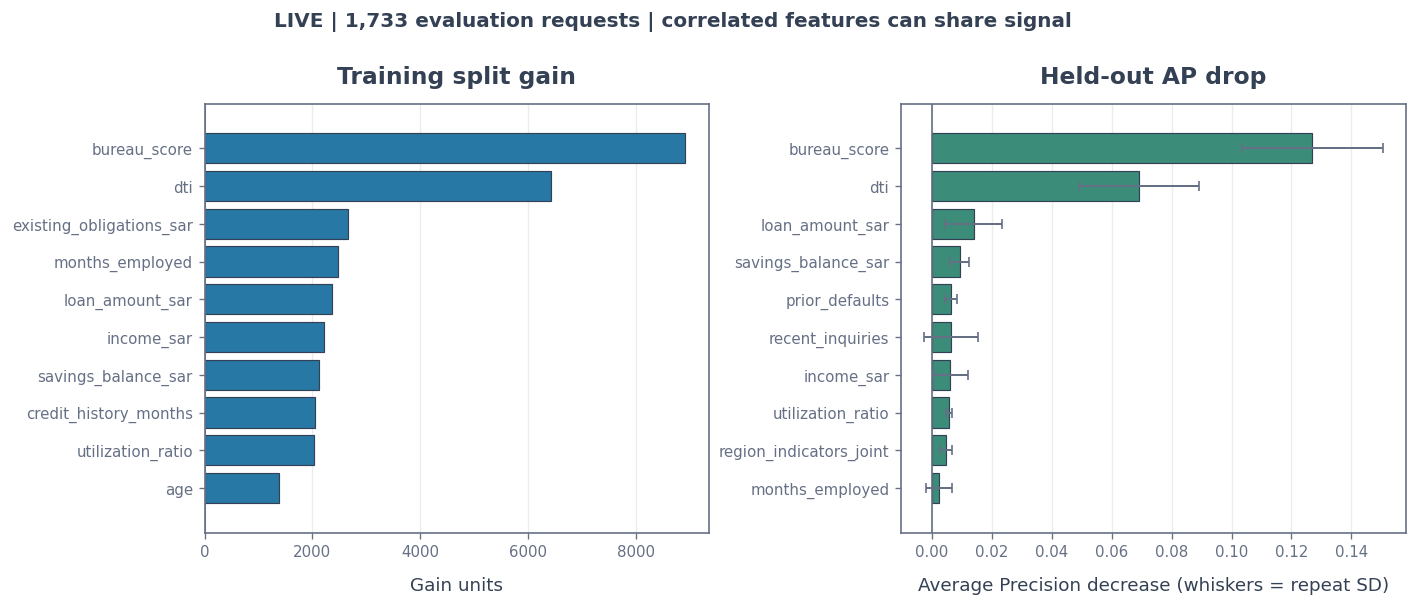

In [3]:
permutation = permutation_report(model, parts["evaluation"], contract, config)

display(
    permutation[
        ["feature_group", "mean_ap_drop", "repeat_sd", "training_gain"]
    ].head(10).round(4)
)

fig, (ax_gain, ax_drop) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.20,
    right=0.97,
    top=0.82,
    bottom=0.17,
    wspace=0.38
)

plot_settings = [
    (ax_gain, "training_gain", "Training split gain"),
    (ax_drop, "mean_ap_drop", "Held-out AP drop")
]

for ax, column, title in plot_settings:
    top = permutation.nlargest(10, column).sort_values(column)

    ax.barh(
        top.feature_group,
        top[column],
        color="#2878A5" if column == "training_gain" else "#3B8C78",
        edgecolor="#344054",
        linewidth=0.7,
        xerr=top.repeat_sd if column == "mean_ap_drop" else None,
        error_kw={
            "ecolor": "#667085",
            "elinewidth": 1.2,
            "capsize": 3
        } if column == "mean_ap_drop" else None
    )

    ax.axvline(0, color="#667085", linewidth=1)
    ax.set_title(title, pad=12, fontweight="semibold")
    ax.set_xlabel(
        "Gain units" if column == "training_gain"
        else "Average Precision decrease (whiskers = repeat SD)",
        labelpad=10
    )

    ax.grid(axis="x", color="#E8EDF2", linewidth=0.8)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#667085")
        spine.set_linewidth(1)

    ax.tick_params(axis="both", labelsize=9, colors="#667085")
    ax.margins(y=0.08)

fig.suptitle(
    f"LIVE | {len(evaluation):,} evaluation requests | correlated features can share signal",
    fontsize=12,
    fontweight="semibold",
    color="#344054",
    y=0.96
)

fig.savefig(
    ARTIFACTS / "permutation_importance.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 4. Global SHAP and its unit

TreeSHAP explains the raw (class-weighted) model on a fixed random sample of 300 evaluation requests. The unit is **log-odds**, not probability points: base value + the sum of a request's SHAP values equals its raw margin, and only that sum goes through a sigmoid. These values explain the raw score, not the calibrated probability.

,feature,mean_absolute_shap_log_odds
4,bureau_score,0.9042
5,dti,0.5437
2,loan_amount_sar,0.3490
10,savings_balance_sar,0.2169
9,existing_obligations_sar,0.2022
8,prior_defaults,0.1830
6,months_employed,0.1584
1,income_sar,0.1549
7,recent_inquiries,0.1492
13,utilization_ratio,0.1287


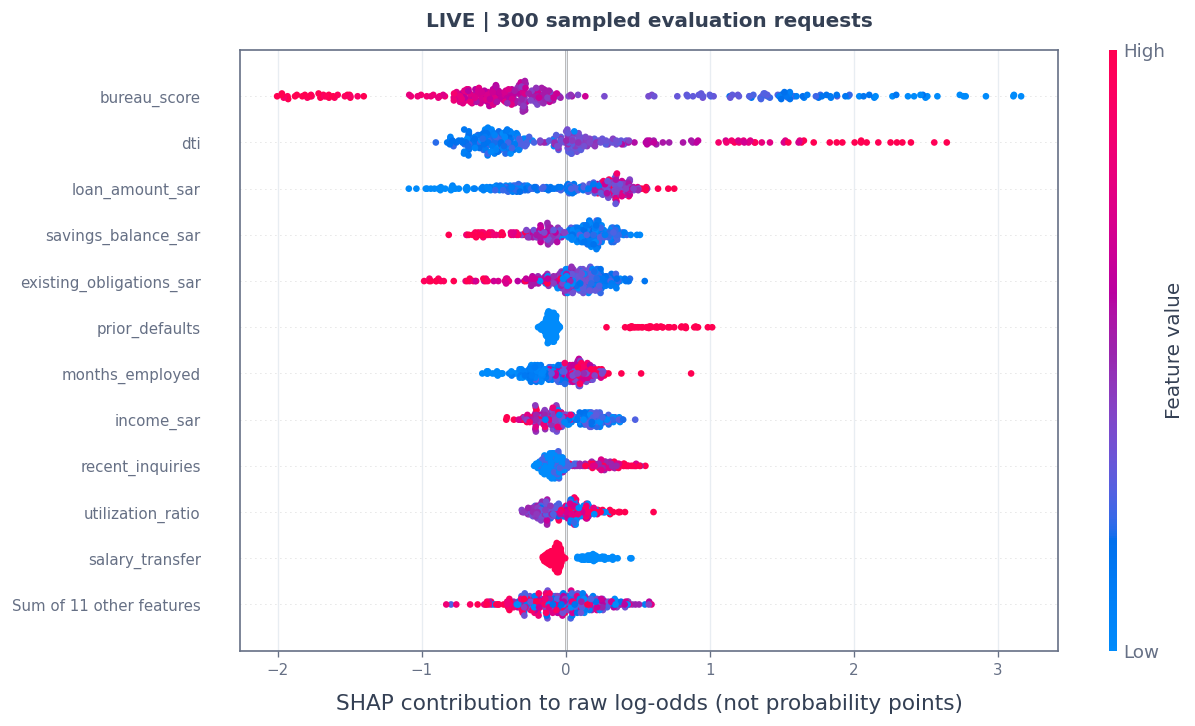

Maximum additivity error: 5.6968318951078345e-15


In [4]:
try:
    if USE_SHAP_EXAMPLE:
        raise ShapBudgetExpired("Educational example requested.")
    shap_arrays, shap_metadata = explain_sample(
        model, parts["evaluation"], contract, config
    )
except ShapBudgetExpired:
    shap_arrays, shap_metadata = load_shap_example(
        ROOT / "data/day4_shap_example.npz",
        ROOT / "data/day4_shap_example.json",
        model, parts["evaluation"], contract, ASSESSMENT_MODE
    )

import shap

EXPLANATION_SOURCE = shap_metadata["source"]

if EXPLANATION_SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE: for discussion only, not your own run. Re-run SHAP later.")

explanation = shap.Explanation(
    values=shap_arrays["values"],
    base_values=shap_arrays["base_values"],
    data=shap_arrays["data"],
    feature_names=list(shap_arrays["feature_names"])
)

shap_global = (
    pd.DataFrame({
        "feature": shap_arrays["feature_names"],
        "mean_absolute_shap_log_odds": np.abs(shap_arrays["values"]).mean(axis=0)
    })
    .sort_values("mean_absolute_shap_log_odds", ascending=False)
)

display(shap_global.head(10).round(4))

plt.figure(figsize=(11, 6.5), dpi=120)

shap.plots.beeswarm(
    explanation,
    max_display=12,
    show=False,
    plot_size=(11, 6.5)
)

ax = plt.gca()

ax.set_xlabel(
    "SHAP contribution to raw log-odds (not probability points)",
    color="#344054",
    labelpad=10
)

ax.set_title(
    f"{EXPLANATION_SOURCE} | {len(shap_arrays['application_ids'])} sampled evaluation requests",
    fontsize=12,
    fontweight="semibold",
    color="#344054",
    pad=14
)

ax.set_facecolor("white")
ax.grid(axis="x", color="#E8EDF2", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#667085")
    spine.set_linewidth(1)

ax.tick_params(axis="both", colors="#667085", labelsize=9)

plt.savefig(
    ARTIFACTS / "shap_beeswarm.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Maximum additivity error:", shap_metadata["max_additivity_error"])

## 5. Explain one high-score request

The request with the highest raw score inside the SHAP sample is chosen **without** looking at its real outcome. We list the three features that pushed its score up the most and draw a waterfall. A reason code says what the model used, not why the applicant would default. We also nudge `bureau_score` by +/-1 to see if the top reasons stay the same.

TR-009585 | raw score = 0.9031 | calibrated probability = 0.4795


,feature,meaning,value_used,was_imputed,contribution_log_odds
0,bureau_score,Fictional bureau score at application,497.0000,False,2.269325
1,dti,Obligations plus proposed principal-only insta...,1.2806,False,1.198145
2,loan_amount_sar,Requested principal,93437.2900,False,0.200725


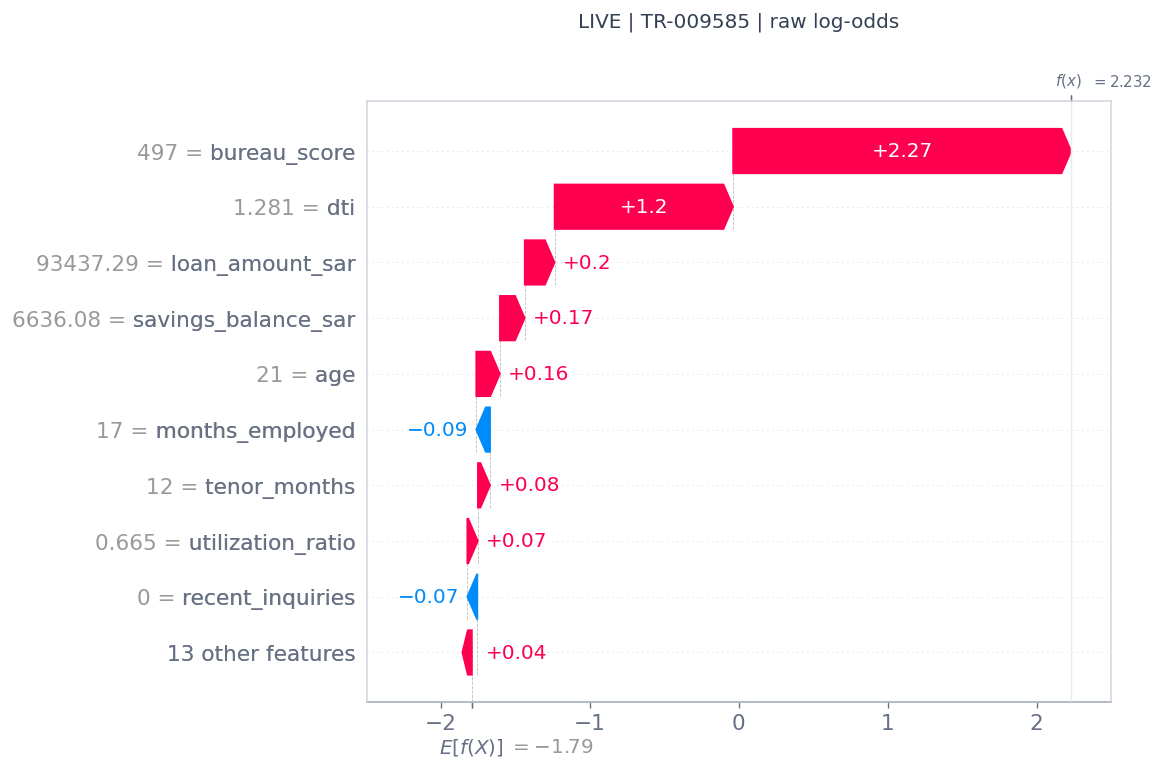

,perturbation,bureau_score_used,raw_probability,calibrated_probability,top_positive_features,shared_top_reasons,reference_reasons,source
0,bureau_score +0,497.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
1,bureau_score -1,496.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
2,bureau_score +1,498.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE


In [5]:
local_index = int(np.argmax(shap_arrays["raw_margin"]))
local_id = str(shap_arrays["application_ids"][local_index])

case = parts["evaluation"].set_index("application_id", drop=False).loc[[local_id]]

descriptions = {
    f["name"]: f["description_ar"]
    for f in contract["features"]
}

descriptions_en = {
    f["name"]: f["description_en"]
    for f in contract["features"]
}

reasons = reason_codes(
    shap_arrays["values"][local_index],
    shap_arrays["feature_names"],
    shap_arrays["data"][local_index],
    descriptions
)

reasons["application_id"] = local_id
reasons["was_imputed"] = [
    bool(case.iloc[0][name] != case.iloc[0][name])
    for name in reasons.feature
]
reasons["source"] = EXPLANATION_SOURCE
reasons["meaning"] = reasons.feature.map(descriptions_en)

raw_local = float(expit(shap_arrays["raw_margin"][local_index]))
cal_local = float(map_probability(raw_local, mapping))

print(
    f"{local_id} | raw score = {raw_local:.4f} | "
    f"calibrated probability = {cal_local:.4f}"
)

reasons_display = reasons[
    [
        "feature",
        "meaning",
        "value_used",
        "was_imputed",
        "contribution_log_odds"
    ]
]

display(reasons_display)

plt.figure(figsize=(11, 6.5), dpi=120)

shap.plots.waterfall(
    explanation[local_index],
    max_display=10,
    show=False
)

ax = plt.gca()
ax.set_title(
    f"{EXPLANATION_SOURCE} | {local_id} | raw log-odds",
    fontsize=12,
    color="#344054",
    pad=45
)

ax.set_facecolor("white")
ax.grid(
    axis="x",
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.8
)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#D0D5DD")
    spine.set_linewidth(0.9)

ax.tick_params(colors="#667085", labelsize=9)

plt.savefig(
    ARTIFACTS / "shap_waterfall.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

if EXPLANATION_SOURCE == "LIVE":
    local_checks = local_stability(
        model,
        case,
        contract,
        mapping
    )

    local_checks["source"] = "LIVE"

    display(local_checks)

else:
    local_checks = pd.DataFrame(
        columns=[
            "perturbation",
            "bureau_score_used",
            "raw_probability",
            "calibrated_probability",
            "top_positive_features",
            "shared_top_reasons",
            "reference_reasons",
            "source"
        ]
    )

    print(
        "The local perturbation check is skipped in example mode; "
        "do not claim it ran."
    )

## 6. Test calibration on a separate period

The sigmoid is learned on the calibration rows only, and the fitted model and calibrator are then frozen. Because the raw scores come from a class-weighted model, they overstate the real default rate. We compare raw and calibrated scores on the evaluation period with **Brier score** (lower is better), **ECE** (average gap between predicted and observed rate) and a 10-bin reliability plot with counts. Calibration is monotone, so it changes probabilities but not the ranking: ROC-AUC and AP stay equal.

,rows,positives,roc_auc,average_precision,brier,ece,log_loss
raw,1733,139,0.770804,0.258677,0.113027,0.146871,0.357993
sigmoid,1733,139,0.770804,0.258677,0.067112,0.022486,0.246749


Measured change (after - before): Brier -0.04592, ECE -0.12438


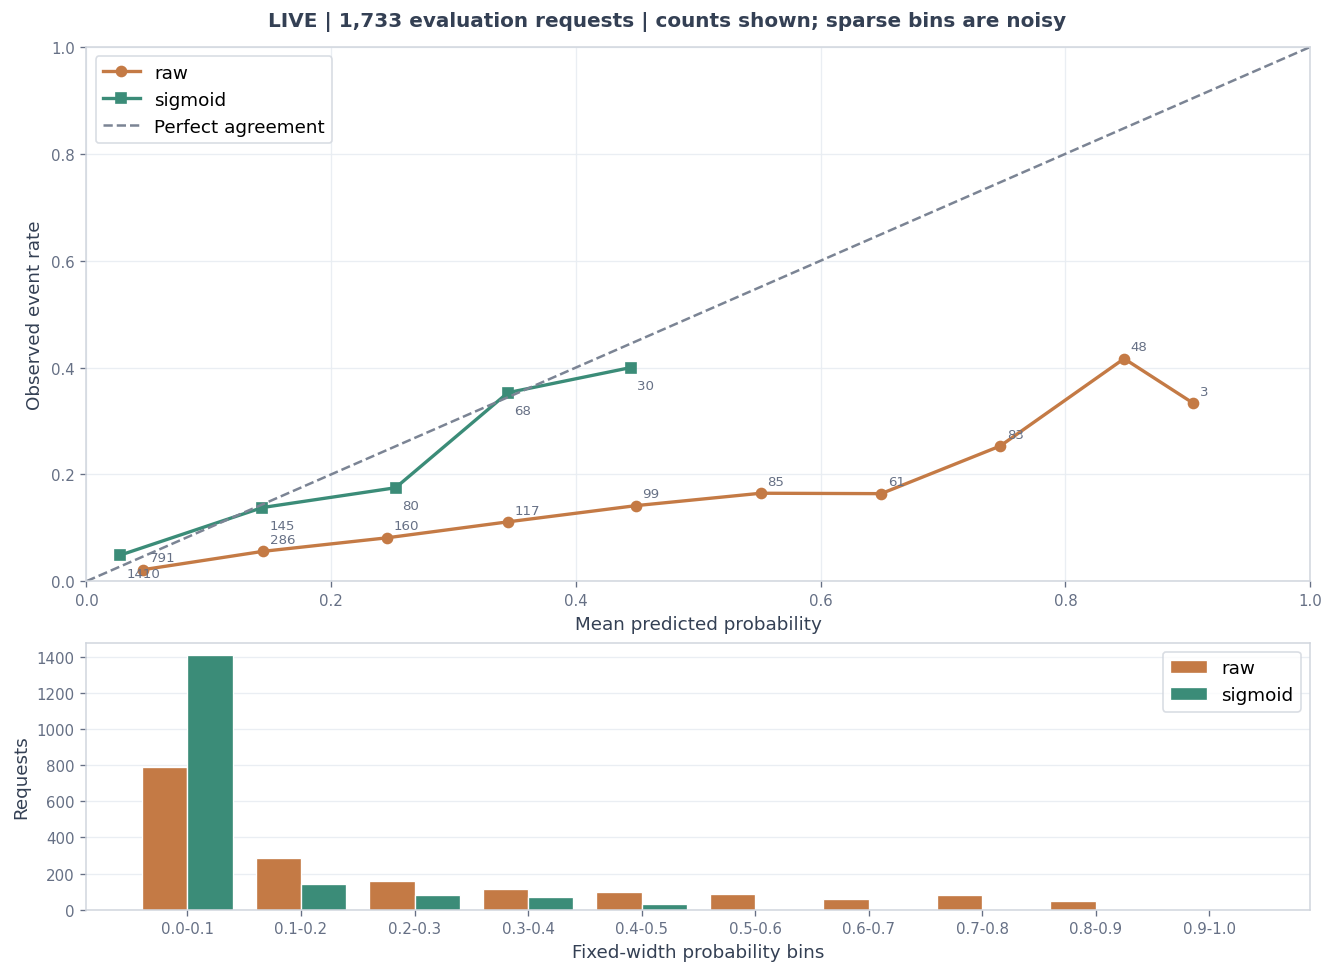

In [6]:
calibration_metrics, bin_tables = {}, []

for label, column in [
    ("raw", "raw_probability"),
    ("sigmoid", "calibrated_probability")
]:
    calibration_metrics[label] = probability_metrics(
        evaluation[TARGET],
        evaluation[column]
    )

    table = reliability_table(
        evaluation[TARGET],
        evaluation[column]
    )

    table["variant"] = label
    bin_tables.append(table)

reliability = pd.concat(bin_tables, ignore_index=True)

metrics_display = pd.DataFrame(calibration_metrics).T[
    [
        "rows",
        "positives",
        "roc_auc",
        "average_precision",
        "brier",
        "ece",
        "log_loss"
    ]
].round(5)

display(metrics_display)

brier_delta = (
    calibration_metrics["sigmoid"]["brier"]
    - calibration_metrics["raw"]["brier"]
)

ece_delta = (
    calibration_metrics["sigmoid"]["ece"]
    - calibration_metrics["raw"]["ece"]
)

print(
    f"Measured change (after - before): "
    f"Brier {brier_delta:+.5f}, ECE {ece_delta:+.5f}"
)

fig, (ax_cal, ax_cnt) = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    dpi=120,
    layout="constrained",
    gridspec_kw={"height_ratios": [2, 1]}
)

colors = {
    "raw": "#C47A45",
    "sigmoid": "#3B8C78"
}

markers = {
    "raw": "o",
    "sigmoid": "s"
}

for label in ["raw", "sigmoid"]:
    color = colors[label]
    marker = markers[label]

    bins = reliability[reliability.variant == label]
    filled = bins[bins["count"] > 0]

    ax_cal.plot(
        filled.mean_probability,
        filled.observed_rate,
        marker=marker,
        markersize=6,
        linewidth=2,
        color=color,
        label=label
    )

    for row in filled.itertuples():
        ax_cal.annotate(
            str(row.count),
            (row.mean_probability, row.observed_rate),
            xytext=(4, 5 if label == "raw" else -13),
            textcoords="offset points",
            fontsize=8,
            color="#667085"
        )

    ax_cnt.bar(
        bins["bin"] + (-0.2 if label == "raw" else 0.2),
        bins["count"],
        width=0.4,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        label=label
    )

ax_cal.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="#7B8494",
    label="Perfect agreement"
)

ax_cal.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Mean predicted probability",
    ylabel="Observed event rate"
)

ax_cal.legend(frameon=True, edgecolor="#D0D5DD")
ax_cal.grid(
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.9
)
ax_cal.set_axisbelow(True)

ax_cnt.set(
    xticks=np.arange(10),
    xticklabels=[
        f"{i / 10:.1f}-{(i + 1) / 10:.1f}"
        for i in range(10)
    ],
    ylabel="Requests",
    xlabel="Fixed-width probability bins"
)

ax_cnt.legend(frameon=True, edgecolor="#D0D5DD")
ax_cnt.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.9
)
ax_cnt.set_axisbelow(True)

for ax in [ax_cal, ax_cnt]:
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#D0D5DD")
        spine.set_linewidth(0.9)

    ax.tick_params(colors="#667085", labelsize=9)
    ax.xaxis.label.set_color("#344054")
    ax.yaxis.label.set_color("#344054")

fig.suptitle(
    f"LIVE | {len(evaluation):,} evaluation requests | "
    "counts shown; sparse bins are noisy",
    fontsize=12,
    color="#344054",
    fontweight="600"
)

fig.savefig(
    ARTIFACTS / "reliability_curve.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 7. What the stability interval covers (and what it does not)

A paired bootstrap resamples **customers** (not rows, because one customer can have several requests) with the model and calibrator held fixed. The interval therefore reflects evaluation-sample noise only. It does not include model refitting, calibration refitting or future drift. The two quarterly figures are descriptive, not a test.

,period,variant,rows,positives,average_precision,brier,ece
0,2024Q3,raw,836,78,0.27457,0.11528,0.13397
1,2024Q3,sigmoid,836,78,0.27457,0.07760,0.03229
2,2024Q4,raw,897,61,0.27050,0.11093,0.15890
3,2024Q4,sigmoid,897,61,0.27050,0.05734,0.02434


Paired customer-cluster 95% percentile intervals:


,lower,upper
raw_ap,0.19744,0.33785
calibrated_ap,0.19744,0.33785
brier_change,-0.05418,-0.03741


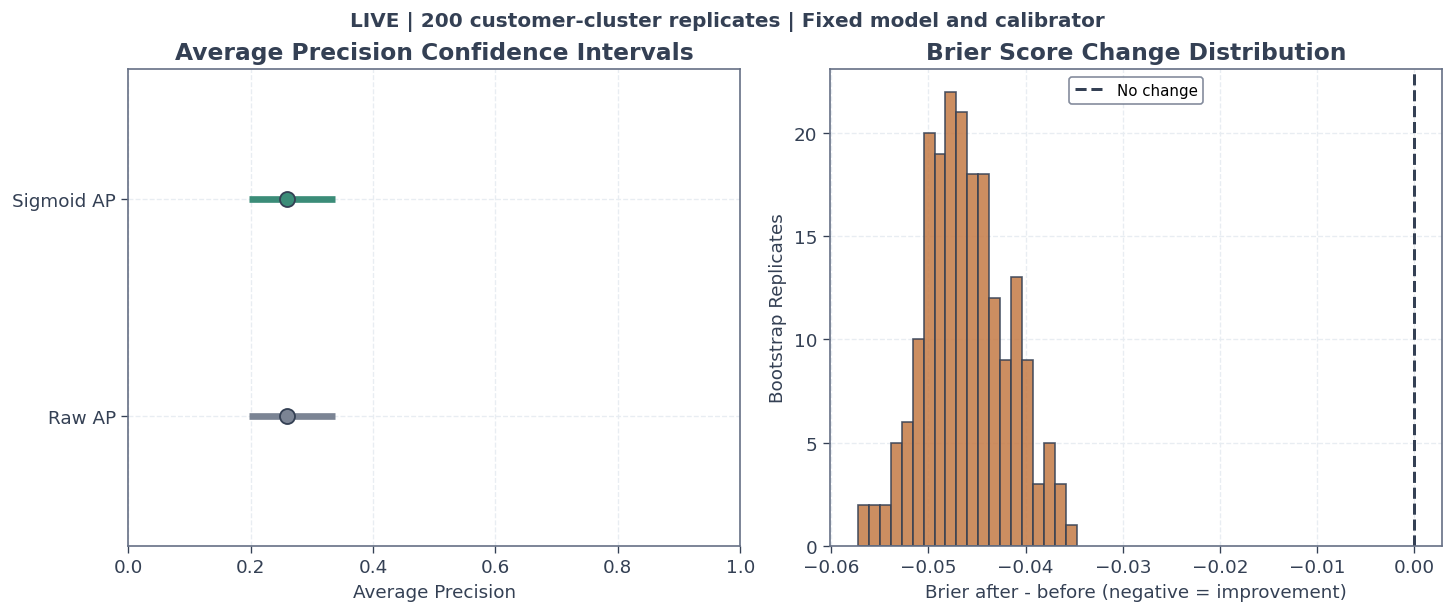

In [7]:
bootstrap, stability_summary = cluster_bootstrap(evaluation, config)

quarter = pd.to_datetime(evaluation.application_date).dt.to_period("Q").astype(str)

period_rows = []

for period, frame in evaluation.groupby(quarter):
    for variant, column in [
        ("raw", "raw_probability"),
        ("sigmoid", "calibrated_probability")
    ]:
        period_rows.append({
            "period": period,
            "variant": variant,
            **probability_metrics(frame[TARGET], frame[column])
        })

period_metrics = pd.DataFrame(period_rows)

display(
    period_metrics[
        ["period", "variant", "rows", "positives",
         "average_precision", "brier", "ece"]
    ].round(5)
)

stability_summary["period_ap_sample_sd"] = {
    variant: float(frame.average_precision.std(ddof=1))
    for variant, frame in period_metrics.groupby("variant")
}

print("Paired customer-cluster 95% percentile intervals:")

interval_table = pd.DataFrame({
    key: stability_summary[key]
    for key in ("raw_ap", "calibrated_ap", "brier_change")
}).T

display(interval_table.round(5))

COLORS = {
    "main": "#2878A5",
    "raw": "#7B8494",
    "calibrated": "#3B8C78",
    "histogram": "#C47A45",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_ap, ax_hist) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    dpi=120,
    layout="constrained"
)

for i, (key, variant) in enumerate([
    ("raw_ap", "raw"),
    ("calibrated_ap", "sigmoid")
]):
    interval = stability_summary[key]

    color = (
        COLORS["raw"] if variant == "raw"
        else COLORS["calibrated"]
    )

    if interval is not None:
        ax_ap.hlines(
            i,
            interval["lower"],
            interval["upper"],
            color=color,
            linewidth=4,
            zorder=2
        )

        ax_ap.plot(
            calibration_metrics[variant]["average_precision"],
            i,
            marker="o",
            markersize=9,
            color=color,
            markeredgecolor=COLORS["edge"],
            markeredgewidth=1.1,
            zorder=3
        )

ax_ap.set(
    yticks=[0, 1],
    yticklabels=["Raw AP", "Sigmoid AP"],
    xlabel="Average Precision",
    xlim=(0, 1),
    ylim=(-0.6, 1.6),
    title="Average Precision Confidence Intervals"
)

ax_hist.hist(
    bootstrap.brier_change,
    bins=20,
    color=COLORS["histogram"],
    alpha=0.85,
    edgecolor=COLORS["edge"],
    linewidth=1.0
)

ax_hist.axvline(
    0,
    color=COLORS["edge"],
    linewidth=1.8,
    linestyle="--",
    label="No change"
)

ax_hist.set(
    xlabel="Brier after - before (negative = improvement)",
    ylabel="Bootstrap Replicates",
    title="Brier Score Change Distribution"
)

ax_hist.legend(
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"]
)

for ax in (ax_ap, ax_hist):
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"LIVE | {stability_summary['valid']} customer-cluster replicates | "
    "Fixed model and calibrator",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "stability_summary.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 8. Does the review zone fit capacity?

The raw threshold was chosen on the policy role only (loss `10 x FN + FP`, 12% capacity) and carried to the calibrated scale through the sigmoid. Around it we add a diagnostic band of +/-0.02 probability to see how many extra requests sit near the cut-off. A request counted as both a flag and "near threshold" is counted once. If the combined review set exceeds capacity, the correct report is `CAPACITY_REVIEW_REQUIRED`, not a quiet change of the limit.

,threshold,flagged,fn,fp,loss_units,capacity,feasible,calibrated_threshold,selection_role
0,0.5882,68,34,47,387.0,70,True,0.1733,policy


,period,rows,capacity,risk_flags,near_threshold,candidate_review,risk_within_capacity,candidate_within_capacity,loss_units
0,2024Q3,836,100,97,23,109,True,False,536.0
1,2024Q4,897,107,109,21,122,False,False,444.0


CAPACITY_REVIEW_REQUIRED | Do not retune on the evaluation role.


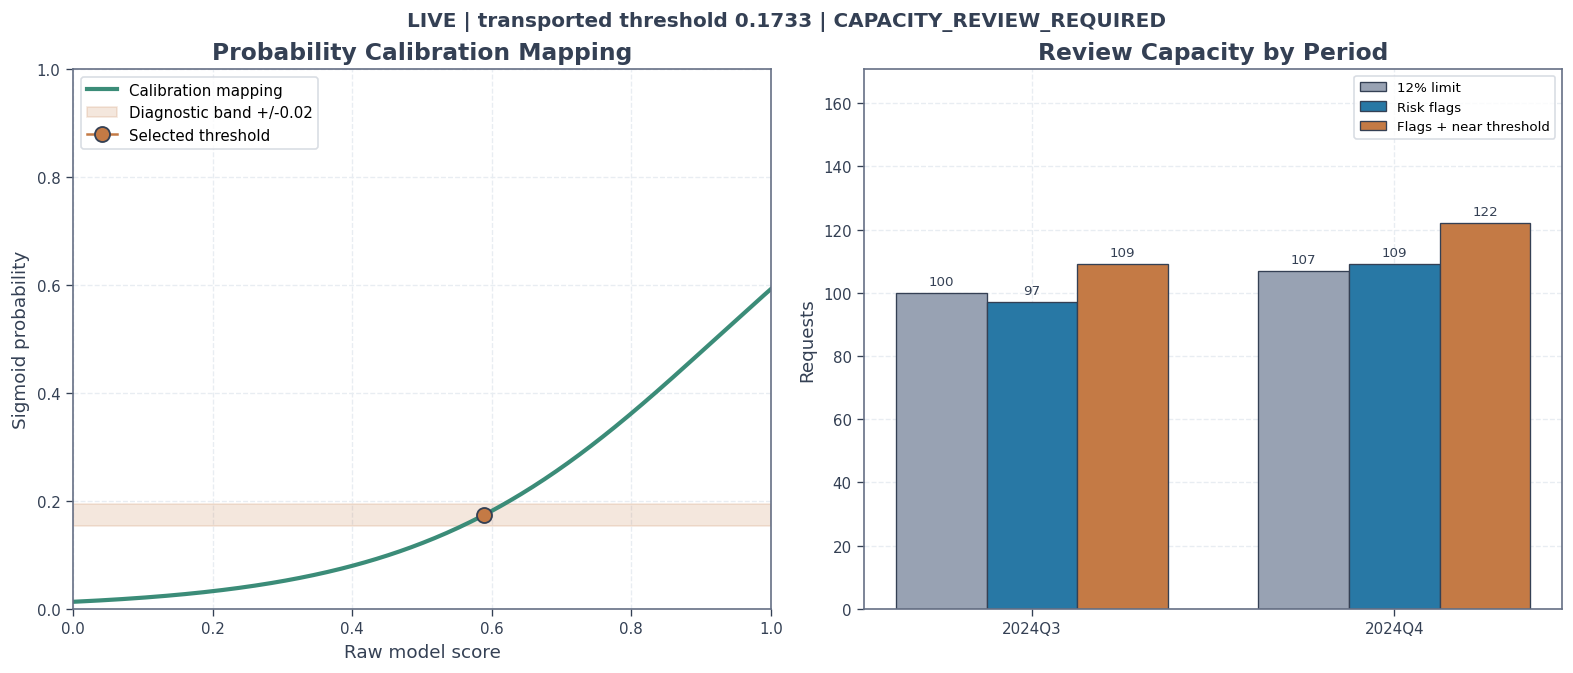

In [8]:
review_flags, capacity_audit, review_band = review_audit(
    evaluation,
    chosen_policy["threshold"],
    calibrated_threshold,
    config.review_half_width
)

policy_status = (
    "CAPACITY_REVIEW_REQUIRED"
    if not capacity_audit.candidate_within_capacity.all()
    else "WITHIN_OBSERVED_CAPACITY"
)

display(
    pd.DataFrame([{
        **chosen_policy,
        "calibrated_threshold": calibrated_threshold,
        "selection_role": "policy"
    }]).round(4)
)

display(capacity_audit.round(4))

print(policy_status, "| Do not retune on the evaluation role.")

COLORS = {
    "main": "#2878A5",
    "green": "#3B8C78",
    "orange": "#C47A45",
    "grey": "#98A2B3",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_map, ax_cap) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=120,
    layout="constrained"
)

grid = np.linspace(0, 1, 300)

ax_map.plot(
    grid,
    map_probability(grid, mapping),
    color=COLORS["green"],
    linewidth=2.5,
    label="Calibration mapping"
)

ax_map.axhspan(
    review_band["lower"],
    review_band["upper"],
    color=COLORS["orange"],
    alpha=0.18,
    label="Diagnostic band +/-0.02"
)

ax_map.plot(
    chosen_policy["threshold"],
    calibrated_threshold,
    marker="o",
    markersize=9,
    color=COLORS["orange"],
    markeredgecolor=COLORS["edge"],
    markeredgewidth=1.1,
    label="Selected threshold",
    zorder=4
)

ax_map.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Raw model score",
    ylabel="Sigmoid probability",
    title="Probability Calibration Mapping"
)

ax_map.legend(
    loc="upper left",
    fontsize=9,
    frameon=True,
    edgecolor="#D0D5DD"
)

pos = np.arange(len(capacity_audit))

bar_settings = [
    (-0.25, "capacity", "12% limit", COLORS["grey"]),
    (0.0, "risk_flags", "Risk flags", COLORS["main"]),
    (0.25, "candidate_review", "Flags + near threshold", COLORS["orange"])
]

for shift, column, label, color in bar_settings:
    bars = ax_cap.bar(
        pos + shift,
        capacity_audit[column],
        width=0.25,
        label=label,
        color=color,
        edgecolor=COLORS["edge"],
        linewidth=0.8
    )

    ax_cap.bar_label(
        bars,
        padding=3,
        fontsize=8,
        color=COLORS["text"]
    )

ax_cap.set(
    xticks=pos,
    xticklabels=capacity_audit.period,
    ylabel="Requests",
    title="Review Capacity by Period",
    ylim=(0, max(1, capacity_audit.candidate_review.max()) * 1.4)
)

ax_cap.legend(
    fontsize=8,
    frameon=True,
    edgecolor="#D0D5DD"
)

for ax in (ax_map, ax_cap):
    ax.set_facecolor("white")

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        labelsize=9,
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"LIVE | transported threshold {calibrated_threshold:.4f} | {policy_status}",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "review_zone.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 9. Interpretation

In [9]:
responses = {
    "global_local": (
        "Permutation importance and SHAP agree on the top two features: bureau_score (AP drop 0.127, mean "
        "|SHAP| 0.904 log-odds) and dti (0.069, 0.544). Both are global summaries of what the model relies on "
        "across the 1,733 evaluation requests (SHAP uses a 300-request sample). The waterfall for request "
        "TR-009585 is local: bureau_score (+2.27), dti (+1.20) and loan_amount_sar (+0.20) pushed that one "
        "score up."),
    "output_units": (
        "SHAP values are in raw log-odds of the class-weighted model, not probability points. Base value plus "
        "the sum of SHAP equals the raw margin (maximum additivity error about 6e-15), and a sigmoid of that "
        "sum gives the raw score 0.903 for request TR-009585. That raw score is not a calibrated probability: "
        "after the sigmoid calibrator the same request has probability 0.480."),
    "reason_limits": (
        "The reason codes list only features that raised this request's score. They say what the model used, "
        "not why the applicant would default or what to change. None of the three values was imputed, and "
        "moving bureau_score by +/-1 left the raw score (0.9031) and the three top reasons unchanged, but "
        "correlated features can share credit, so this is still model behaviour, not cause."),
    "calibration_evidence": (
        "On 1,733 evaluation rows (139 positives) the sigmoid cut Brier from 0.1130 to 0.0671 and ECE from "
        "0.1469 to 0.0225, while AP (0.2587) and ROC-AUC (0.7708) stayed identical because the mapping is "
        "monotone. The class weights had inflated the raw scores. The calibrator was learned on only 584 "
        "separate rows (40 positives), so it is a small-sample estimate, and sparse bins are noisy."),
    "stability": (
        "The 95% customer-cluster bootstrap (200 valid replicates, 1,520 customers) gives AP between 0.197 and "
        "0.338 and a Brier change between -0.054 and -0.037, so the Brier gain is consistent across resamples "
        "while AP is quite uncertain. The intervals keep the model and calibrator fixed and do not cover "
        "refitting or future drift. The AP spread between the two evaluation quarters (sample SD 0.003) is "
        "descriptive only."),
    "review_capacity": (
        "The raw threshold 0.5882 (0.1733 after calibration) was chosen on the policy role. On the evaluation "
        "role the risk flags were 97 of 100 in 2024Q3 and 109 of 107 in 2024Q4, and adding requests near the "
        "threshold gave 109 and 122, so the review zone exceeds the 12% capacity: CAPACITY_REVIEW_REQUIRED. "
        "I did not raise the limit or retune on the evaluation role; a new policy would need development data "
        "and fresh evidence."),
}
checkpoint = reflection_check(responses, EXPLANATION_SOURCE)
print(checkpoint["status"], "| Fields to complete:", checkpoint["missing"])

READY_FOR_REVIEW | Fields to complete: []


## 10. Export the report and the evidence bundle

This cell writes the CSV and JSON evidence, the six figures, the SHAP sample, the model file, an English interpretability report and one ZIP.

In [10]:
NL = chr(10)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    return value


technical_status = "TECHNICAL_READY" if EXPLANATION_SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
calibration_payload = {
    "source": "LIVE", "evaluation_role": "evaluation", "metrics": calibration_metrics, "mapping": mapping,
    "policy_selection": chosen_policy, "calibrated_threshold": calibrated_threshold,
    "review_band": review_band, "capacity_status": policy_status,
    "brier_change": brier_delta, "ece_change": ece_delta,
    "prior_course_exposure": True, "not_a_final_untouched_test": True}
run_info = {
    "technical_status": technical_status, "learner_status": checkpoint["status"],
    "explanation_source": EXPLANATION_SOURCE, "model_calibration_source": "LIVE", "config": asdict(config),
    "assessment_mode": ASSESSMENT_MODE, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION,
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
    "capacity_status": policy_status, "challenge_used_for_modeling": False, "no_automatic_grade": True}

tables = {
    "day4_roles.csv": assignments, "day4_predictions.csv": predictions,
    "permutation_importance.csv": permutation,
    "day4_shap_global.csv": shap_global.assign(source=EXPLANATION_SOURCE),
    "day4_reason_codes.csv": reasons.drop(columns=["meaning"]), "day4_local_stability.csv": local_checks,
    "day4_reliability_bins.csv": reliability, "day4_period_metrics.csv": period_metrics,
    "day4_bootstrap.csv": bootstrap, "day4_policy_sweep.csv": policy_sweep,
    "day4_review_flags.csv": review_flags, "day4_capacity.csv": capacity_audit}
for name, frame in tables.items():
    frame.to_csv(ARTIFACTS / name, index=False)
np.savez_compressed(ARTIFACTS / "shap_values_sample.npz", **shap_arrays)
model.named_steps["model"].booster_.save_model(str(ARTIFACTS / "day4_model.txt"))

json_files = {
    "calibration_metrics.json": calibration_payload, "day4_shap_metadata.json": shap_metadata,
    "day4_stability_summary.json": stability_summary, "day4_provenance.json": provenance,
    "day4_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day4_run.json": run_info}
for name, payload in json_files.items():
    (ARTIFACTS / name).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False),
                                  encoding="utf-8")

state_line = ("Teaching example, not submittable as your own run" if EXPLANATION_SOURCE != "LIVE"
              else "Ready for review; this is not an approval or a grade")
reason_lines = NL.join(f"- {r.feature} = {r.value_used:g}: {r.meaning} (SHAP {r.contribution_log_odds:+.4f} log-odds; "
                       f"imputed: {r.was_imputed})" for r in reasons.itertuples())
capacity_lines = NL.join(f"- {r.period}: limit {r.capacity}, risk flags {r.risk_flags}, "
                         f"flags + near threshold {r.candidate_review}" for r in capacity_audit.itertuples())
top_feature = shap_global.iloc[0]
report = f"""# Interpretability report | Tamweel Lite

**Status:** {state_line}
**Explanation source:** {EXPLANATION_SOURCE} | **Model and calibration:** LIVE | **Capacity:** {policy_status}

## Model and roles
Class-weighted LightGBM, {config.trees} trees. Target: a synthetic default within 90 days. Roles are separated by time and by customer: fit {len(parts['fit'])} rows, calibration {len(parts['calibration'])} ({int(parts['calibration'][TARGET].sum())} positives), policy {len(parts['policy'])}, evaluation {len(evaluation)}. Gap periods and overlapping customers are excluded. The evaluation data was seen earlier in the course, so it is not an untouched final test.

## Global and local explanation
Permutation importance measures the Average Precision lost on the evaluation rows when a feature is shuffled. SHAP explains the raw model in log-odds: base value + sum of SHAP = raw margin, and a sigmoid of that sum gives the raw score. The values are not probability points and do not explain the calibrated probability.

Most important feature by mean |SHAP|: **{top_feature.feature}** ({top_feature.mean_absolute_shap_log_odds:.4f} log-odds). Largest held-out AP drop: **{permutation.iloc[0].feature_group}** ({permutation.iloc[0].mean_ap_drop:.4f}).

Synthetic request {local_id}: raw score {raw_local:.5f}, calibrated probability {cal_local:.5f}. It was chosen as the highest raw score inside the SHAP sample, without using its real outcome.
{reason_lines}

## Calibration
On {len(evaluation)} rows ({int(evaluation[TARGET].sum())} positives): Brier {calibration_metrics['raw']['brier']:.6f} -> {calibration_metrics['sigmoid']['brier']:.6f}; ECE {calibration_metrics['raw']['ece']:.6f} -> {calibration_metrics['sigmoid']['ece']:.6f}. AP {calibration_metrics['raw']['average_precision']:.6f} -> {calibration_metrics['sigmoid']['average_precision']:.6f} and ROC-AUC {calibration_metrics['raw']['roc_auc']:.6f} -> {calibration_metrics['sigmoid']['roc_auc']:.6f} are unchanged because the mapping is monotone. These are results for this sample, not a promise for the future.

## Stability
{stability_summary['valid']} valid customer-cluster bootstrap replicates, 95% percentile intervals, model and calibrator fixed. They exclude refitting, recalibration and future drift, and do not describe one person's probability. The AP spread between the two evaluation quarters is descriptive only. The bureau_score +/-1 check {'ran; see day4_local_stability.csv' if EXPLANATION_SOURCE == 'LIVE' else 'did not run in example mode'}.

## Threshold and review zone
Raw threshold {chosen_policy['threshold']!r} was chosen on the policy role (loss 10 x FN + FP, 12% capacity) and carried to {calibrated_threshold!r} on the calibrated scale; it was not adjusted using the evaluation role. The diagnostic band [{review_band['lower']:.5f}, {review_band['upper']:.5f}] is +/-0.02 and is not a confidence interval; a request is counted once.
{capacity_lines}

If the review set exceeds capacity, document that a new policy must be designed on development data and tested with new evidence. Do not raise the limit or trim cases after seeing the result. SHAP and reason codes describe the model, not causes or fairness. Loss is in teaching units, not money or grade points. This exercise is not for real lending.
"""
(REPORTS / "INTERPRETABILITY_REPORT.md").write_text(report, encoding="utf-8")

figures = ["permutation_importance.png", "shap_beeswarm.png", "shap_waterfall.png",
           "reliability_curve.png", "stability_summary.png", "review_zone.png"]
bundle_files = list(tables) + list(json_files) + figures + ["environment.json", "shap_values_sample.npz",
                                                            "day4_model.txt"]
with zipfile.ZipFile(ARTIFACTS / "day4_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in bundle_files:
        bundle.write(ARTIFACTS / name, "artifacts/" + name)
    bundle.write(REPORTS / "INTERPRETABILITY_REPORT.md", "reports/INTERPRETABILITY_REPORT.md")
print(f"{technical_status} | {checkpoint['status']} | {EXPLANATION_SOURCE} | CPU")
print(f"Saved {len(bundle_files) + 1} files in day4_artifacts.zip | {policy_status}")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | CPU
Saved 28 files in day4_artifacts.zip | CAPACITY_REVIEW_REQUIRED
